# SEAWAT Tutorial 3: The Elder Free Convection Problem
### SEAWAT FloPy Short Course

This notebook reuses the Henry notebook to build the Elder (1967) free convection problem in the form used by Voss & Souza (1987) and the SEAWAT benchmark (Guo & Langevin, 2002). Dense brine sits on part of the top of a closed box and sinks as fingers. There is no regional flow, so **density alone drives the flow**. The step numbers follow the Henry notebook. Only the changes from the Henry notebook are explained here. The result is saved as an animated GIF at the end.

## Step 0. Setting up the environment
Same as the Henry notebook. Run these cells once every time you connect.

In [1]:
# This cell fixes a Colab problem in which the Run Model cell never finishes,
# caused by a version conflict between Colab's Python 3.13 and the Jupyter client.

import warnings, datetime, jupyter_client.session
warnings.filterwarnings("ignore", category=DeprecationWarning)                        # hide the warnings
jupyter_client.session.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)  # replace the warning-producing function with a warning-free version

import ipykernel.kernelbase
ipykernel.kernelbase.now = jupyter_client.session.utcnow                              # also replace the copy the kernel made at start-up (otherwise the warning keeps appearing)

In [2]:
# Colab does not include FloPy or the SEAWAT executable (swtv4), so we install them at run time.
# On Colab: FloPy 3.11 is installed and swtv4 goes into /usr/local/bin (gone after a runtime reset).
# On a local PC: your own FloPy is used, and swtv4 is downloaded once into the FloPy bin folder.

import sys, os, shutil
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q "flopy<3.12"      # flopy 3.12 needs numpy >= 2.2, which would upgrade Colab's numpy and break numba

import flopy
bindir = Path("/usr/local/bin") if IN_COLAB else Path(os.environ.get("LOCALAPPDATA", Path.home())) / "flopy" / "bin"
swt_exe = shutil.which("swtv4") or shutil.which(str(bindir / "swtv4"))
if swt_exe is None:                   # download swtv4 only if it is not there yet
    bindir.mkdir(parents=True, exist_ok=True)
    flopy.utils.get_modflow(str(bindir), subset="swtv4", quiet=True)
    swt_exe = shutil.which(str(bindir / "swtv4"))
print("FloPy", flopy.__version__, "| swtv4:", swt_exe)  # confirm that both are installed

FloPy 3.12.0 | swtv4: C:\Users\SAM\AppData\Local\flopy\bin\swtv4.EXE


In [3]:
from pathlib import Path                 # file paths

In [4]:
import numpy as np    # array computations

In [5]:
import flopy          # write SEAWAT input files, run the model, read the results

## The problem
- Closed vertical box, 600 m long and 150 m high. No flow through any side.
- Top, 150 m ≤ x ≤ 450 m: brine source, concentration fixed at C = 1 (density 1,200 kg/m³). Bottom: C = 0 (fresh).
- The two top corners are held at zero pressure (constant head) so that the closed box has a reference head.
- The box starts fresh (C = 0). Brine sinks from the top in fingers for 20 years.
- Compared with Henry: no freshwater inflow, a 20 % density contrast instead of 2.5 %, and the salt enters by **diffusion** from the top, not by flow from the side.

## Step 1. Input variables
Values of Voss & Souza (1987), converted to metres and days.

<table style="width:100%; table-layout:auto; border-collapse:collapse; margin:10px 0 16px 0; font-size:0.95em;">
<thead><tr>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Variable</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Henry</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Elder</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Unit</th>
<th style="background:rgba(127,127,127,0.30); font-family:Arial, Helvetica, sans-serif; font-weight:700; text-align:center; vertical-align:middle; padding:6px 10px; border:none;">Meaning</th>
</tr></thead><tbody>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>Lx</code>, <code>Lz</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">2, 1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">600, 150</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">m</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Length and height of the box<sup>3</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>ncol</code>, <code>nlay</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">100, 50</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">60, 20</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">–</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Columns and layers, 10 m × 7.5 m cells. The result depends on the grid (see Step 11)<sup>3</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>hk</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">864</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.411</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">m/day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Hydraulic conductivity, from k = 4.845 × 10⁻¹³ m² and μ = 10⁻³ Pa·s<sup>5</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>prsity</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.35</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">–</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Porosity<sup>7</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>dmcoef</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.570</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">0.308</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">m²/day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Molecular diffusion (3.565 × 10⁻⁶ m²/s). Dispersivity is zero in both<sup>7</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>qinflow</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">5.702</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">–</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">m³/day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">No freshwater inflow, so no WEL package<sup>6</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:none;"><code>cmax</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">35</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">1</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">–</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:none;">Brine concentration (relative, 0 to 1)<sup>6,7</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;"><code>denseslp</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">0.7143</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">200</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">kg/m³</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:rgba(127,127,127,0.13); border-bottom:none;">Density = 1000 + 200 C, so 1,200 kg/m³ for the brine<sup>8</sup></td></tr>
<tr><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:center; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;"><code>t_end</code></td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">1.5</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">7,300</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">day</td><td style="font-family:'Times New Roman', Times, serif; padding:5px 10px; border:none; text-align:left; vertical-align:top; background:transparent; border-bottom:1.5px solid currentColor;">20 years of simulation<sup>3,7</sup></td></tr>
</tbody></table>

<sup>n</sup> Step in which the variable is used.

In [6]:
Lx, Lz = 600.0, 150.0          # length and height (m)
ncol, nlay = 60, 20            # columns and layers: 10 m x 7.5 m cells
nrow, delc = 1, 1.0            # one row: vertical 2-D section
delr, delv = Lx / ncol, Lz / nlay
top = Lz
botm = np.linspace(top - delv, 0.0, nlay)
xc = delr * (np.arange(ncol) + 0.5)            # cell-centre x (m)
zc = top - delv * (np.arange(nlay) + 0.5)      # cell-centre z (m)

hk = 4.845e-13 * 1000.0 * 9.81 / 1.0e-3 * 86400.0   # k * rho * g / mu -> 0.411 m/day
prsity = 0.1
dmcoef = 3.565e-6 * 86400.0                          # 0.308 m2/day

cmax = 1.0                     # brine concentration (relative)
denseref, densemax_ = 1000.0, 1200.0
denseslp = (densemax_ - denseref) / cmax             # 200

year = 365.0
t_end = 20 * year              # 7,300 days

## Step 2. Create the SEAWAT model
A normal folder `elder_ws` is used instead of a temporary one, so the results can be kept. The `mf2005` / `mt3dms` warnings can be ignored, as in Henry.

In [7]:
import shutil
workspace = Path("elder_ws")
shutil.rmtree(workspace, ignore_errors=True)   # start from an empty folder (old output files are not overwritten cleanly)
workspace.mkdir(exist_ok=True)
name, ipakcb = "seawat_elder", 53
swt = flopy.seawat.Seawat(name, exe_name=swt_exe, model_ws=str(workspace))

C:\Users\SAM\Documents\Groundwater\.venv\Lib\site-packages\flopy\mbase.py:105: UserWarning: The program mf2005 does not exist or is not executable.
  warn(
C:\Users\SAM\Documents\Groundwater\.venv\Lib\site-packages\flopy\mbase.py:105: UserWarning: The program mt3dms does not exist or is not executable.
  warn(


## Step 3. DIS package: grid and time
One stress period of 20 years, split into 20 MODFLOW time steps of one year (only for head and flow output). The transport steps are much shorter and are chosen by MT3DMS.

In [8]:
nstp = 20
dis = flopy.modflow.ModflowDis(swt, nlay, nrow, ncol, nper=1, delr=delr, delc=delc, laycbd=0,
                               top=top, botm=botm, perlen=t_end, nstp=nstp)

## Step 4. BAS package: boundary cells and starting head
Only the two top corner cells are constant head (−1), instead of the whole sea column in Henry. All other sides are no flow. The starting head is 150 m, the hydrostatic freshwater head.

In [9]:
ibound = np.ones((nlay, nrow, ncol), dtype=np.int32)
ibound[0, 0, [0, -1]] = -1                           # top-left and top-right corner cells
bas = flopy.modflow.ModflowBas(swt, ibound=ibound, strt=top)

## Step 5. LPF, PCG and OC packages
Same as Henry with the Elder conductivity. Heads and flows are saved at the end of every year.

In [10]:
lpf = flopy.modflow.ModflowLpf(swt, hk=hk, vka=hk, ipakcb=ipakcb)
pcg = flopy.modflow.ModflowPcg(swt, mxiter=100, iter1=200, hclose=1.0e-7, rclose=1.0e-7)
oc = flopy.modflow.ModflowOc(swt, stress_period_data={(0, k): ["save head", "save budget"] for k in range(nstp)},
                             compact=True)

## Step 6. SSM data
No WEL package: nothing is pumped in. SSM only says that water entering through the two corner cells is fresh (C = 0).

In [11]:
itype = flopy.mt3d.Mt3dSsm.itype_dict()
ssm_data = {0: [[0, 0, j, 0.0, itype["BAS6"]] for j in (0, ncol - 1)]}

## Step 7. MT3DMS packages
The brine source and the fresh bottom are **constant concentration cells** (`icbund = −1`), set in BTN instead of SSM. The salt enters only by diffusion from these cells. Concentrations are saved every quarter year for the animation.

In [12]:
icbund = np.ones((nlay, nrow, ncol), dtype=np.int32)
sconc = np.zeros((nlay, nrow, ncol))                 # box starts fresh
src = (xc > 150.0) & (xc < 450.0)                    # brine source on the top, 150 m < x < 450 m
icbund[0, 0, src] = -1;  sconc[0, 0, src] = cmax     # top source: C = 1
icbund[-1, 0, :] = -1;   sconc[-1, 0, :] = 0.0       # bottom: C = 0

timprs = np.arange(0.25, 20.0 + 1e-9, 0.25) * year   # output every 0.25 year (80 frames)

btn = flopy.mt3d.Mt3dBtn(swt, icbund=icbund, sconc=sconc, prsity=prsity, nprs=len(timprs), timprs=timprs,
                         ifmtcn=0, chkmas=False, nprobs=10, nprmas=10, dt0=0.0, mxstrn=100000)
adv = flopy.mt3d.Mt3dAdv(swt, mixelm=0, percel=1.0, nadvfd=1)       # finite difference, Courant <= 1
dsp = flopy.mt3d.Mt3dDsp(swt, al=0.0, trpt=1.0, trpv=1.0, dmcoef=dmcoef)
gcg = flopy.mt3d.Mt3dGcg(swt, iter1=500, mxiter=1, isolve=2, cclose=1e-7)
ssm = flopy.mt3d.Mt3dSsm(swt, stress_period_data=ssm_data, mxss=10)

## Check the grid and boundary conditions
Red: brine source (C = 1). Blue: fresh bottom (C = 0). Black squares: constant head corners.

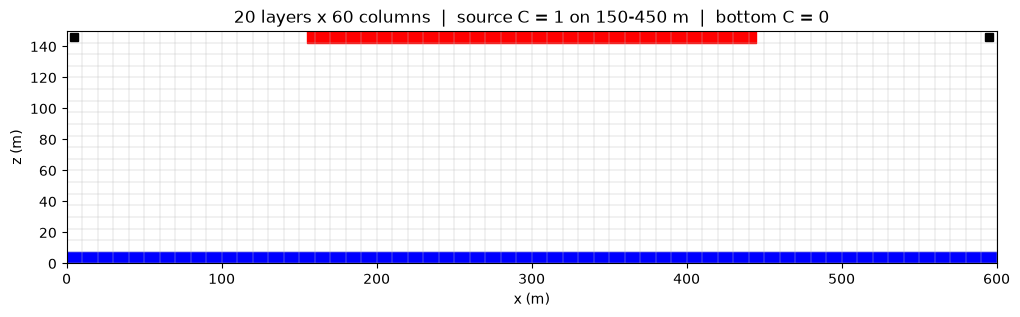

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.vlines(np.arange(ncol + 1) * delr, 0, Lz, color="0.75", lw=0.3)
ax.hlines(np.r_[top, botm], 0, Lx, color="0.75", lw=0.3)
ax.fill_between(xc[src], top - delv, top, color="red", step="mid")
ax.fill_between([0, Lx], 0, delv, color="blue")
ax.plot(xc[[0, -1]], zc[[0, 0]], "ks", ms=6)
ax.set(xlim=(0, Lx), ylim=(0, Lz), xlabel="x (m)", ylabel="z (m)", aspect="equal",
       title=f"{nlay} layers x {ncol} columns  |  source C = {cmax:g} on 150-450 m  |  bottom C = 0")
plt.show()

## Step 8. VDF package
$\rho = 1000 + 200 \times C$. The slope is 200 instead of 0.7143, because C runs from 0 to 1.

In [14]:
vdf = flopy.seawat.SeawatVdf(swt, iwtable=0, densemin=0, densemax=0, denseref=denseref,
                             denseslp=denseslp, firstdt=1.0)

## Step 9. Write the input files and run SEAWAT
Takes a few seconds.

In [15]:
swt.write_input()
success, buff = swt.run_model(silent=True, report=True)
assert success, "SEAWAT did not terminate normally."

## Step 10. Load the concentrations
All 80 snapshots are read into one array with the shape (time, layer, row, column).

In [16]:
import flopy.utils.binaryfile as bf

ucn = bf.UcnFile(workspace / "MT3D001.UCN", model=swt)
times = np.array(ucn.get_times())                    # days
conc_all = ucn.get_alldata()[:, :, 0, :]             # (time, layer, column)
print(len(times), "snapshots from", times[0], "to", times[-1], "days")

80 snapshots from 91.25 to 7300.0 days


## Step 11. Concentration at 1, 2, 4, 10, 15 and 20 years
The classic Elder figure.

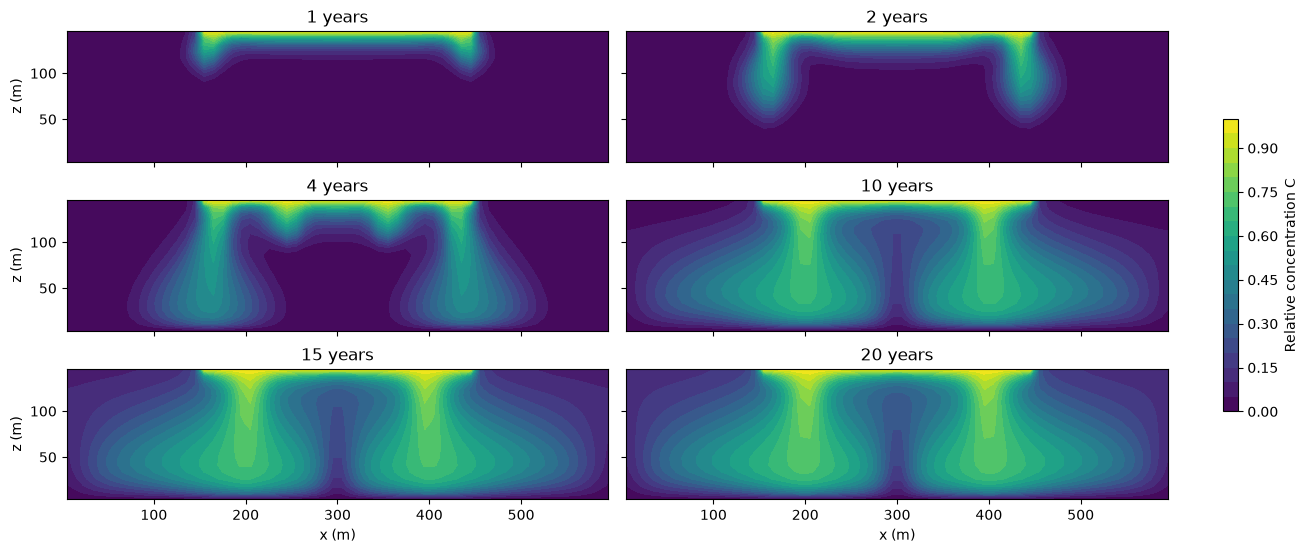

In [17]:
levels = np.linspace(0, cmax, 21)
fig, axes = plt.subplots(3, 2, figsize=(13, 5.4), sharex=True, sharey=True, constrained_layout=True)
for ax, yr in zip(axes.flat, [1, 2, 4, 10, 15, 20]):
    i = np.argmin(np.abs(times - yr * year))
    cf = ax.contourf(xc, zc, conc_all[i], levels=levels, cmap="viridis")
    ax.set(aspect="equal", title=f"{times[i] / year:.0f} years")
for ax in axes[-1]: ax.set_xlabel("x (m)")
for ax in axes[:, 0]: ax.set_ylabel("z (m)")
fig.colorbar(cf, ax=axes, shrink=0.6, label="Relative concentration C")
plt.show()

**Reading the figure**
- Brine first forms a thin dense layer under the source, which becomes unstable and breaks into sinking fingers.
- The fingers merge with time. By 20 years there are **two large plumes**, one under each half of the source, and fresh water rises between them at x = 300 m. The pattern is symmetric about x = 300 m.
- The Elder problem is very sensitive to the grid. On this grid we get the classic two-plume result. A finer grid (for example 120 × 60) gives three fingers with a sinking one in the centre (Simpson & Clement, 2003).

## Step 12. Animate the concentrations as a GIF
Every quarter-year snapshot becomes one frame. The GIF is saved next to this notebook as `elder_concentration.gif`.

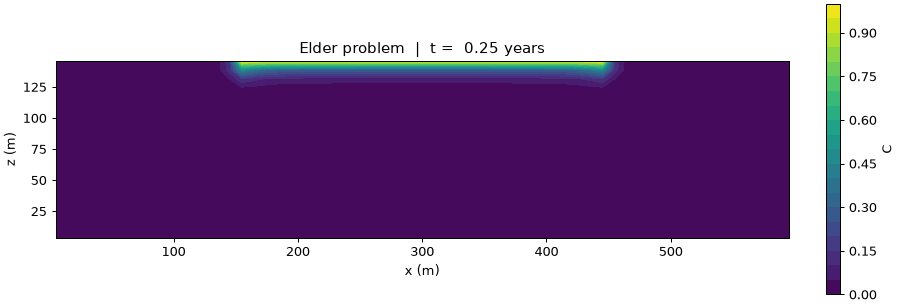

In [18]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
cf = ax.contourf(xc, zc, conc_all[0], levels=levels, cmap="viridis")
fig.colorbar(cf, ax=ax, label="C")

def draw(i):
    ax.clear()
    ax.contourf(xc, zc, conc_all[i], levels=levels, cmap="viridis")
    ax.set(aspect="equal", xlabel="x (m)", ylabel="z (m)", title=f"Elder problem  |  t = {times[i] / year:5.2f} years")

anim = FuncAnimation(fig, draw, frames=len(times))
gif_path = Path("elder_concentration.gif")
anim.save(gif_path, writer=PillowWriter(fps=8), dpi=90)
plt.close(fig)
display(Image(filename=str(gif_path)))

## Step 13. Concentration and flow vectors at 20 years
As Step 12 of Henry. The flows are the last saved budget (20 years). The arrows show convection cells: brine sinks in the fingers and fresh water rises between them.

C:\Users\SAM\Documents\Groundwater\.venv\Lib\site-packages\flopy\utils\binaryfile\__init__.py:2571: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  self.headers.drop(columns=drop_cols, inplace=True)


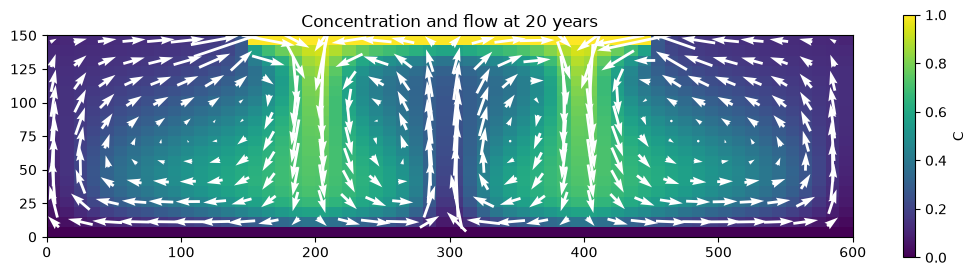

In [19]:
cbb = bf.CellBudgetFile(workspace / f"{name}.cbc")
tb = cbb.get_times()[-1]
qx = cbb.get_data(text="flow right face", totim=tb)[0]
qz = cbb.get_data(text="flow lower face", totim=tb)[0]
qy = np.zeros_like(qx)

fig = plt.figure(figsize=(13, 4.5))
ax = fig.add_subplot(1, 1, 1, aspect="equal")
pmv = flopy.plot.PlotCrossSection(model=swt, ax=ax, line={"row": 0})
arr = pmv.plot_array(ucn.get_data(totim=times[-1]), cmap="viridis")
pmv.plot_vector(qx, qy, -qz, color="white", kstep=2, hstep=2)   # every second cell
plt.colorbar(arr, shrink=0.7, ax=ax, label="C")
ax.set_title(f"Concentration and flow at {tb / year:.0f} years")
plt.show()

## Clean up
Deletes the working folder. Skip it to keep the results. The GIF is not deleted.

In [20]:
ucn.close(); cbb.close()     # close the output files first (Windows cannot delete open files)
shutil.rmtree(workspace, ignore_errors=True)

## Summary
- The Elder problem has no boundary inflow: buoyancy alone drives the flow, so it is a strict test of the density coupling in SEAWAT.
- Constant concentration cells (`icbund = −1` in BTN) give a salt source without a water source.
- The number of plumes depends on the grid: two plumes on 60 × 20, three fingers on 120 × 60.

**Going further**
1. Use `ncol, nlay = 120, 60` in Step 1 and compare the number of fingers at 20 years.
2. Halve `denseslp` in Step 1 (density 1,100 kg/m³). How much slower do the fingers sink?

**References**
- Elder, J. W. (1967). Transient convection in a porous medium. *Journal of Fluid Mechanics*, 27(3), 609–623.
- Voss, C. I., & Souza, W. R. (1987). Variable density flow and solute transport simulation of regional aquifers containing a narrow freshwater-saltwater transition zone. *Water Resources Research*, 23(10), 1851–1866.
- Guo, W., & Langevin, C. D. (2002). User's guide to SEAWAT. USGS Techniques of Water-Resources Investigations 6-A7.
- Simpson, M. J., & Clement, T. P. (2003). Theoretical analysis of the worthiness of Henry and Elder problems as benchmarks of density-dependent groundwater flow models. *Advances in Water Resources*, 26(1), 17–31.